We perform cylinder fitting. 

In [1]:
# First manage the imports
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

from bayes_shape_fitting.inference.likelihoods import MarginalLikelihood, ClosestPointLikelihood
from bayes_shape_fitting.inference.posterior import MarginalPosterior
from bayes_shape_fitting.inference.priors import Prior, GaussianPrior, UniformPrior
from bayes_shape_fitting.inference.samplers.map_estimation import MAPOptimizer
from bayes_shape_fitting.inference.noise_functions import IsotropicNoise
from bayes_shape_fitting.inference.source_densitites import BetaSourceDensity, UniformSourceDensity
from bayes_shape_fitting.models.shapes.shape_examples import shape_cases
from bayes_shape_fitting.utils.sample_data import simulate_measurement

Importing bayes_shape_fitting.inference
Importing bayes_shape_fitting.models.shapes
Importing bayes_shape_fitting.utils


In [2]:
np.random.seed(24)

In [3]:
# first we define the shape case
case = shape_cases[5]

shape = case["shape"]
theta = case["theta"]
init_theta = case["init_params"]

In [4]:
# we define a uniform source density
source_density_true = UniformSourceDensity(n_dim = 2, fixed_params=np.array([0.5,0.5, 0.6, 0.15]),domain_low = shape.domain_low, domain_high = shape.domain_high, periodic = shape.periodic ) # params are [c_0,w_0,c_1,w_1]

In [5]:
# the noise function is chosen to be isotropic
noise_function = IsotropicNoise(dim_param=shape.parameter_dim, dim_ambient=shape.ambient_dim, fixed_params=0.1)

In [6]:
# simulate a measurement of 100 points
measurement = simulate_measurement(shape, theta, source_density_true, noise_function, num_samples=100)

In [7]:
# for formulating a posterior, we need to define likelihood and prior
# we choose a Uniform density

source_density = UniformSourceDensity(n_dim = 2,domain_low = shape.domain_low, domain_high = shape.domain_high, periodic = shape.periodic )

In [8]:
# then the likelihood 
#likelihood = MarginalLikelihood(shape=shape, source_density=source_density_true, noise_function=noise_function, num_samples = 50)

likelihood = ClosestPointLikelihood(shape=shape, source_density=source_density_true, noise_function=noise_function)

In [9]:
# let's also define a prior on the Source density
mean = np.array([0.5,0.2, 0.6, 0.15])  # resembels mean and variance of the gaussian
cov =  np.diag([0.01,0.01,0.01,0.01]) 
prior = GaussianPrior(mean=mean, cov=cov)

In [10]:
# and the posterior
posterior = MarginalPosterior(shape=shape, measurement=measurement, likelihood=likelihood)

In [11]:
# now we define the optimizer
optimizer = MAPOptimizer(method='L-BFGS-B', verbose=True)

In [12]:
# let us define an initial guess for the source density
init_source_density = np.array([0.5,0.2, 0.6, 0.15])    
init = np.hstack([init_theta,init_source_density])

In [13]:
# perform the MAP estimation
bounds = shape.bounds + 2*[(0,1),(0.1,0.5)]
result = optimizer.optimize(posterior, init_theta, shape_bounds=shape.bounds)

MAP Optimization with L-BFGS-B
Initial log posterior: -112.825271
Optimizing blocks: shape
Number of optimized parameters: 7
Using box constraints: 7 bounds


Optimization Complete
Success: True
Message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Final log posterior: 33.982890
Improvement: 146.808162
Iterations: 37
Function evaluations: 352
Runtime: 0.148s
----------------------------------------------------------------------
⚠ Abnormal termination detected
• First-order optimality not satisfied: ||g||_inf=4.973e-02 > tol=1.000e-04
Gradient infinity-norm: 4.973e-02



In [14]:
theta_map = result.theta_map[0:shape.get_n_params()]

Importing bayes_shape_fitting.visualization


(<Figure size 1000x800 with 1 Axes>,
 <Axes3D: xlabel='x', ylabel='y', zlabel='z'>)

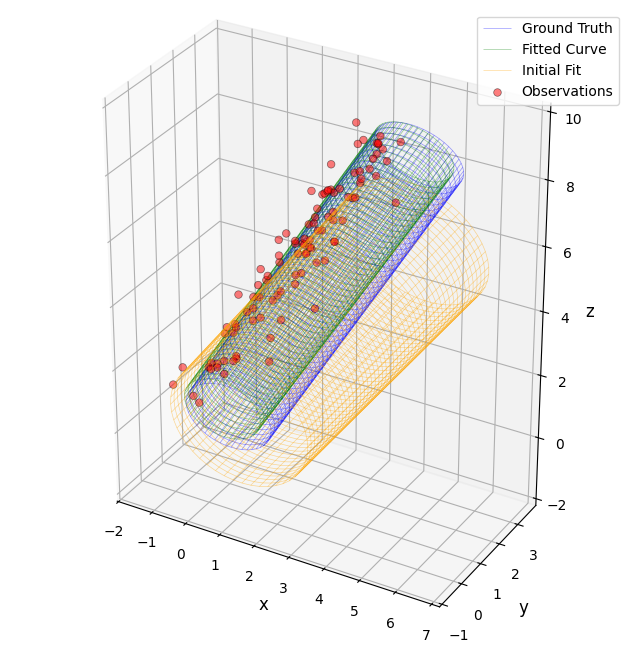

In [15]:
# we plot the result of the fit
from bayes_shape_fitting.visualization.plotting_3d import ShapePlotter3D

plotter = ShapePlotter3D()

fig, ax = plotter.plot_shape(shape, theta, label="Ground Truth")
plotter.plot_shape(shape, theta_map, ax=ax, label="Fitted Curve", color="green")
plotter.plot_shape(shape, init_theta, ax=ax, label="Initial Fit", color="orange")
plotter.plot_observations(observations=measurement, ax=ax)

In [ ]:
# let's do the animation
from bayes_shape_fitting.visualization.animation_3d import ShapePlotterAnimations3D

animator = ShapePlotterAnimations3D()
# we need to crop the param_history to only get the shape values
param_history = [r[:shape.get_n_params()] for r in result.param_history]

# first plot the real shape
fig, ax, = plotter.plot_shape(shape, theta, label="Ground Truth", color = "red")
plotter.plot_observations(observations=measurement, ax=ax)
ani = animator.animate_param_history(shape, param_history, ax = ax)
ani.save("Animate_cylinder.gif", writer="pillow", fps=2)
from IPython.display import Image
Image("Animate_cylinder.gif")

In [ ]:
source_params_history = [r[shape.get_n_params():] for r in result.param_history]
source_params_history

In [ ]:
shape_params_history = [r[:shape.get_n_params()] for r in result.param_history]
shape_params_history